# Transmitting and Receiving Over-the-Air (OTA)

In this notebook, we will transmit and receive a signal over the air (using the acoustic channel). We will leverage all the concepts and techniques we have developed in the previous notebooks; i.e., the required functionality is provided by the functions and classes in the `dc_632_26` package.

## Imports

The standard modules, including `sounddevice`, are imported along with our custom `dc_632_26` package, which provides the necessary functions and classes for transmitting and receiving signals over the air.

In [84]:
## import standard modules 
# Numpy is a fundamental package for scientific computing in Python. It provides support for arrays, matrices, and many mathematical functions.
import numpy as np

# SciPy is a Python library used for scientific and technical computing. It builds on NumPy and provides additional functionality for optimization, integration, interpolation, eigenvalue problems, and more
import scipy.signal  as signal     # Import the signal processing module from SciPy

# Matplotlib is a plotting library for creating static, animated, and interactive visualizations in Python. The 'inline' magic command allows the plots to be displayed directly in the notebook.
import matplotlib.pyplot as plt
%matplotlib inline

# tweak the appearance of the plots
plt.rcParams['figure.figsize'] = (10, 6)  # Set the default figure size for plots

# seaborn is a statistical data visualization library based on Matplotlib. It provides a high-level interface for drawing attractive and informative statistical graphics.
import seaborn as sns
# Set the context for Seaborn plots to 'talk', which is suitable for presentations and larger text sizes.
sns_context = 'talk' 
sns.set_theme(context=sns_context, style="ticks", palette="deep")

# Enable audio transmission and reception
import sounddevice as sd

In [85]:
# import modules from dc_632_26
from dc_632_26.sources import RandomBitSource
from dc_632_26.pulses import SqrtRaisedCosinePulse
from dc_632_26.constellations import standard_constellation
from dc_632_26.modulation import modulation
from dc_632_26.pulse_shaper import PulseShaper
from dc_632_26.poly_phase_correlator import PolyPhaseCorrelator
from dc_632_26.estimator import Estimator
from dc_632_26.demodulation import GenericSlicer
from dc_632_26.tracking import PLL, ALL
from dc_632_26.freq_shift import Upconverter

## Transmitter

The transmitted signal consists of:

* length-31 preamble; BPSK modulated
* 2000-bit payload; QPSK modulated
* pulse-shaped with a square-root raised cosine filter with roll-off factor 0.5
* the baseband signal is 64 times oversampled and then
* upconverted to the carrier frequency of 10KHz
* the sound device operates at a rate of 48KHz 
  - The resulting signal bandwidth is approximately 48KHHz/64 * (1 + 0.5) = 1125 Hz

In [86]:
## Signal parameters
# preamble - this is a length 31 M-sequence
preamble_bits = np.array([1, 0, 0, 0, 0, 1, 0, 0, 1, 0, 1, 1, 0, 
                          0, 1, 1, 1, 1, 1, 0, 0, 0, 1, 1, 0, 1, 
                          1, 1, 0, 1, 0], dtype=np.uint8)
K = len(preamble_bits)
preamble_constellation = standard_constellation.BPSK
preamble_symbols = modulation(preamble_bits, preamble_constellation)

# payload - 2000 random bits
N = 2000
payload_bits = RandomBitSource().get_bits(N)
payload_constellation = standard_constellation.QAM16
payload_symbols = modulation(payload_bits, payload_constellation)

# pulse shaping
fsT = 64
pulse = SqrtRaisedCosinePulse(num_samples=10*fsT, oversamp=fsT, alpha=0.5)
ps = PulseShaper(pulse, fsT)

sig = ps.generate_waveform(np.concatenate((preamble_symbols, payload_symbols)))

# upconversion
fc = 10e3
fs = 48e3
upconverter = Upconverter(fc, fs)
sig_up = upconverter.process(sig)

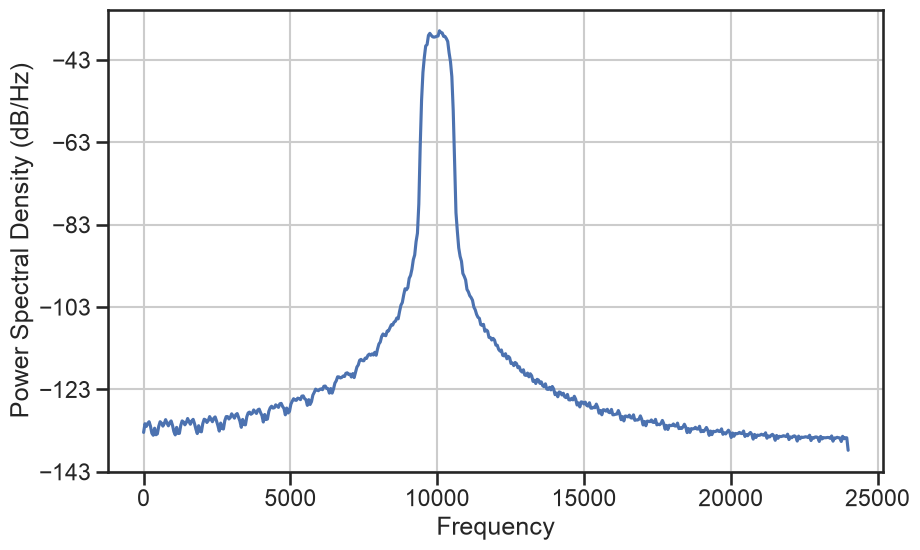

In [87]:
plt.psd(sig_up, NFFT=1024, Fs=fs)
plt.show()

## Transmission

The generated passband signal is transmitted over the audio channel from speaker to microphone.

In [88]:
## send and receive signals via audio
# to prevent the recorded signal from being cut-off, append some zeros to the transmitted signal
recorded_signal = sd.playrec(np.concatenate([sig_up, np.zeros(int(0.3*fs))]), fs, channels=1)

sd.wait()  # wait until playback and recording is finished

recorded_signal = recorded_signal.flatten()  # flatten the recorded signal to 1D array

### PSD and Time-Domain Plot of Recorded Signal

To make sure that we received the transmitted signal correctly, we can examine both the power spectral density (PSD) and the time-domain plot of the recorded signal.

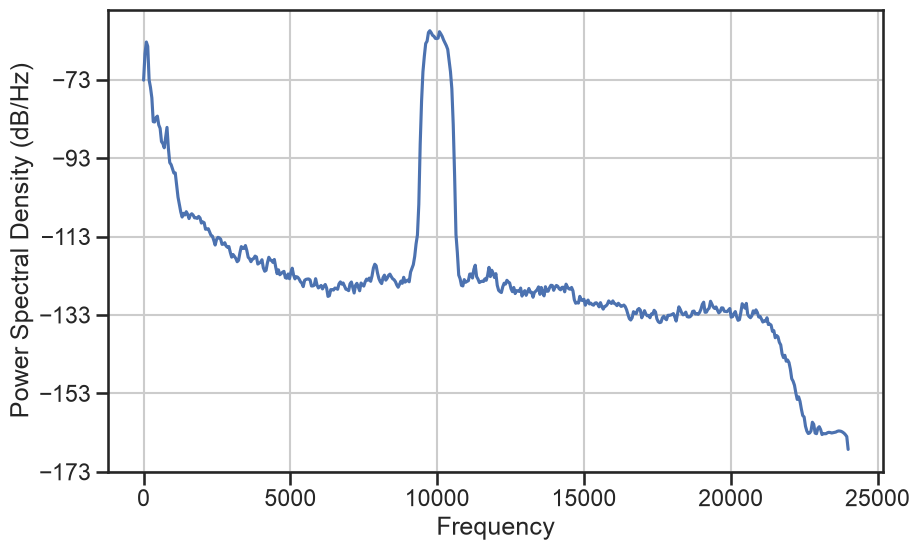

In [89]:
plt.psd(recorded_signal, NFFT=1024, Fs=fs)
plt.show()

This looks very good. The transmitted signal is clearly visible at 10KHz. The "usual" background noise at low frequencies is present and there seems to be a harmonic at 20KHz as well.

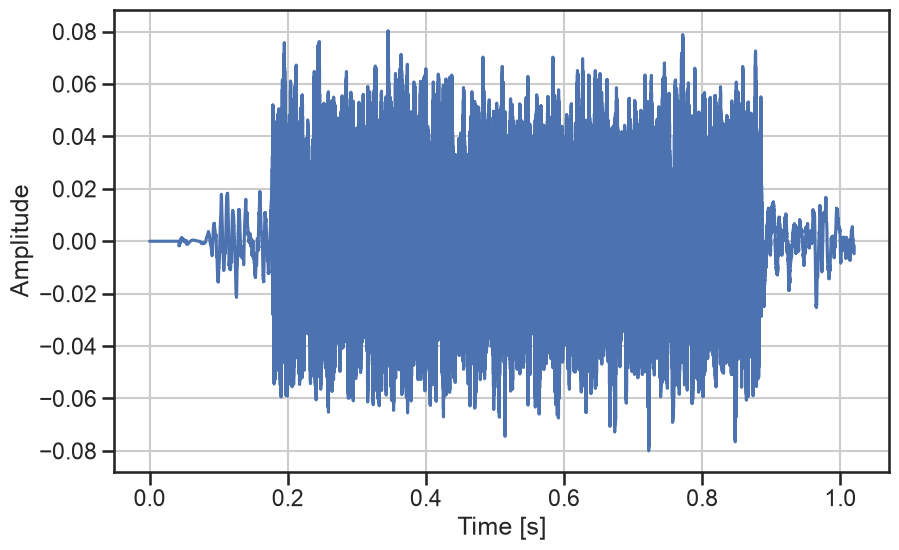

In [90]:
plt.plot(np.arange(len(recorded_signal))/fs, recorded_signal)
plt.xlabel('Time [s]')
plt.ylabel('Amplitude')
plt.grid()
plt.show()

The entire signal appears to have been captured. The "usual" lag at the start is present. But, the signal itself is clearly visible and matches the expected duration (1.33s) of the transmitted signal.

Prior to receiver processing, we will down-convert the recorded signal to baseband and reduce the sample rate by a factor of 8, so that the received signal is 8 times oversampled.

In [91]:
## down-convert recorded signal to baseband
t = np.arange(len(recorded_signal))/fs
recorded_signal_bb = recorded_signal * np.exp(-1j*2*np.pi*fc*t)

# down-sample the baseband signal (using SciPy's decimate function)
fsT_r = 8
ds_factor = fsT // fsT_r  # down-sampling factor
recorded_signal_bb_ds = signal.decimate(recorded_signal_bb, ds_factor, ftype='fir')  

Look at the power spectral density of the down-sampled baseband signal to make sure that it still looks correct.

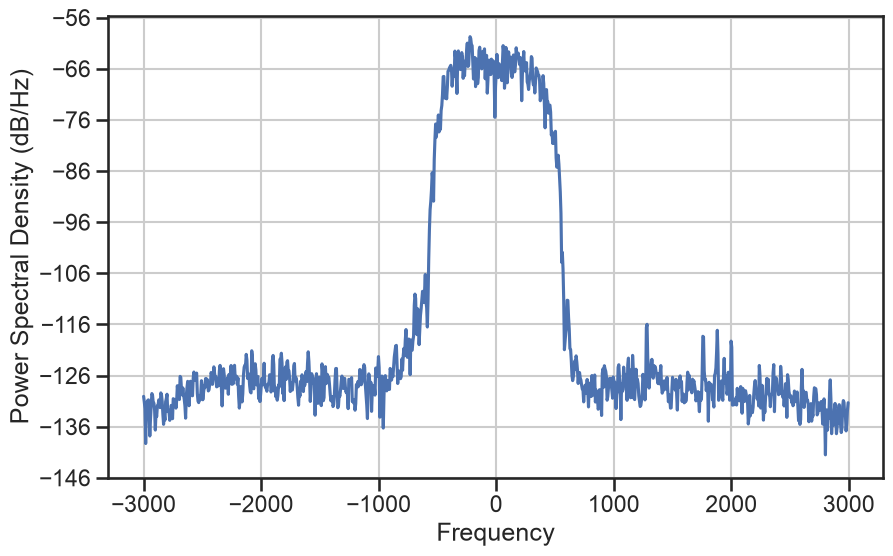

In [92]:
plt.psd(recorded_signal_bb_ds, NFFT=1024, Fs=fs/ds_factor)
plt.show()

Very good!

And the magnitude of the down-sampled baseband signal should also look correct.


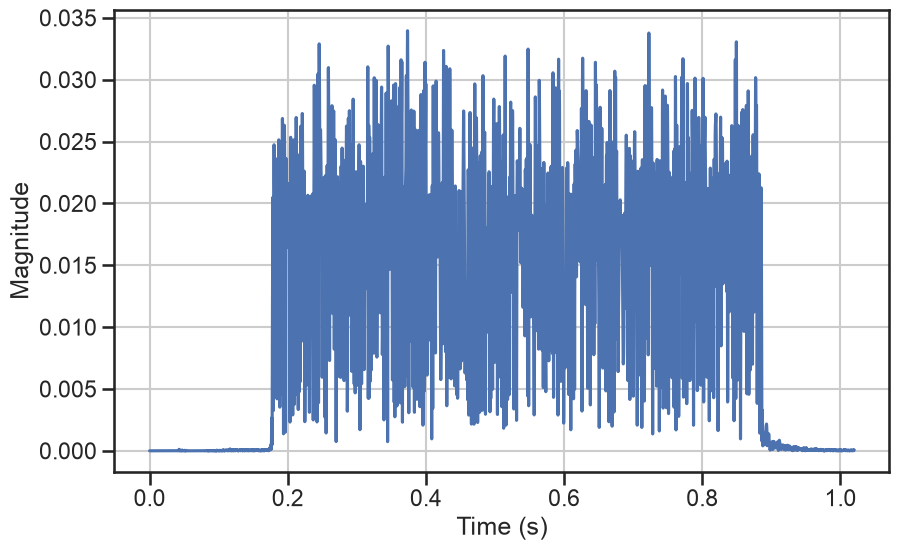

In [93]:
plt.plot(np.arange(len(recorded_signal_bb_ds))/fs*ds_factor, np.abs(recorded_signal_bb_ds))
plt.grid(True)
plt.xlabel('Time (s)')
plt.ylabel('Magnitude')
plt.show()

## Receiver Processing

Processing in the receiver begins with the steps that we discussed previously. We are not using the `Receiver` class directly so that we have access to the various signals in the processing chain. The tracking loops will be integrated into the `Receiver` at a later time. The processing steps include:
* matched filtering,
* computing correlations for the different sampling phases
* locating the preamble, including the best sampling phase,
* followed by initial parameter estimates derived from the preamble.

In [94]:
rr = recorded_signal_bb_ds

## matched filter output
# we need a different pulse than the transmitter because the oversampling factor is different
mf_hh = SqrtRaisedCosinePulse(num_samples=10*fsT_r, oversamp=fsT_r, alpha=0.5)._generate_samples()
mf_out = np.convolve(rr, np.flipud(mf_hh.conj()))

# prepare for the polyphase correlation loop
num_phases = fsT_r
num_symbols = len(mf_out) // num_phases
corrs = np.zeros((num_phases, num_symbols), dtype=complex)
mags = np.zeros((num_phases, num_symbols), dtype=float)

# instantiate the polyphase correlator
pp_corr = PolyPhaseCorrelator(preamble_symbols, num_phases=num_phases)

for k in range(num_symbols):
    for p in range(num_phases):
        sample = mf_out[k*num_phases + p]
        corr, mag = pp_corr.update(sample)
        corrs[p, k] = corr
        mags[p, k] = mag

# locate peak correlation
m_ind = np.argmax(np.abs(corrs), axis=1)
p_ind = np.argmax([np.abs(corrs[i, m_ind[i]]) for i in range(num_phases)])
k_ind = m_ind[p_ind]

print(f"Peak correlation at phase index {p_ind}, symbol index {k_ind}")
print(f"Preamble extends from symbol index {k_ind-len(preamble_symbols) + 1} to {k_ind}")

Peak correlation at phase index 7, symbol index 168
Preamble extends from symbol index 138 to 168


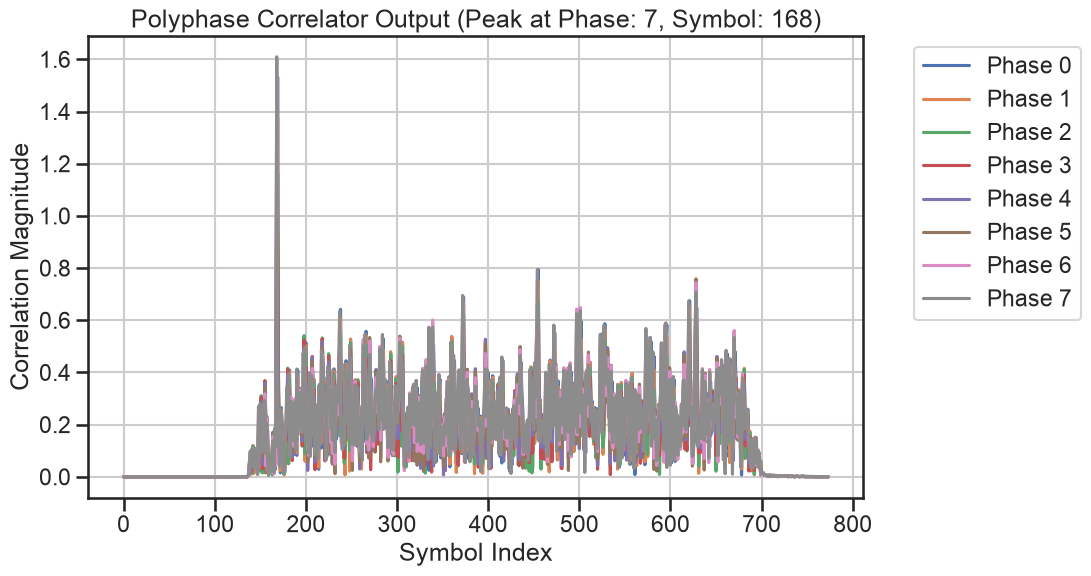

In [95]:
for p in range(num_phases):
    plt.plot(np.abs(corrs[p, :]), label=f'Phase {p}')
plt.xlabel('Symbol Index')
plt.ylabel('Correlation Magnitude')
plt.title(f'Polyphase Correlator Output (Peak at Phase: {p_ind}, Symbol: {k_ind})')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid()
plt.show()

We can now isolate the preamble and the payloads based on the peak correlation location. 

The received preamble symbols are used to compute initial estimates for amplitude, phase, and frequency.

In [96]:
mf_out_pind = mf_out[p_ind::fsT_r]
preamble_symbols_received = mf_out_pind[k_ind-len(preamble_symbols) + 1:k_ind+1]
payload_symbols_received = mf_out_pind[k_ind+1:k_ind+1+N]

estimator = Estimator(preamble_symbols, 2)

freq_offset, complex_gain, noise_var_est = estimator.estimate(preamble_symbols_received)

print(f"Estimated frequency offset: {freq_offset:.6f} per symbol")
print(f"Estimated gain: {np.abs(complex_gain):.6f}")
print(f"Estimated phase: {np.angle(complex_gain)/np.pi:.6f}*pi")
print(f"Estimated noise variance: {noise_var_est:.6f}")

Estimated frequency offset: -0.000053 per symbol
Estimated gain: 0.051924
Estimated phase: -0.432294*pi
Estimated noise variance: 0.000046


### Tracking loops

We choose to start our tracking loops with the preamble. For that purpose, we
* initialize the states of the integrators in the loop
* then run the loops using the known training symbols

#### Initialize the tracking loops using the preamble

In [109]:
## Instantiating Tracking Loops
pll = PLL()  # Phase-Locked Loop
all = ALL()  # Amplitude-Locked Loop

# Initialize the state of the tracking loops from the preamble estimates
# TO DO: improve the I/F to PLL and ALL to make this more obvious
pll.set_frequency(freq_offset)
pll.set_phase(np.angle(complex_gain))
all.set_gain(np.abs(complex_gain))
#all.integrator.state = 1/np.abs(complex_gain)

In [110]:
Z_hat = preamble_symbols_received
x = np.zeros_like(Z_hat, dtype=complex)
y = np.zeros_like(Z_hat, dtype=complex)

## now run the tracking loop over the preamble symbols (length K)
for n in range(len(preamble_symbols)):
    # first the PLL
    x[n] = pll.correct(Z_hat[n])        # this goes to amplitude loop
    pll.update(x[n], preamble_symbols[n])

    # then the amplitude loop, input is the phase corrected input x[n]
    y[n] = all.correct(x[n])   # x[n] is the input from above
    all.update(y[n], preamble_symbols[n])

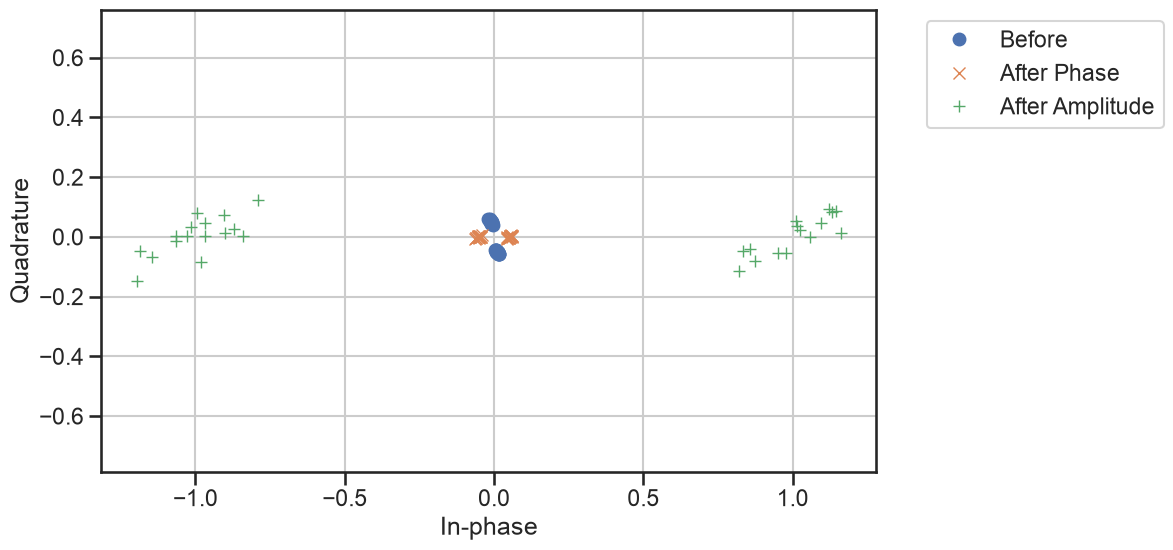

In [111]:
# Scatter plot of input before and after phase and amplitude corrections
plt.plot(Z_hat.real, Z_hat.imag, 'o', label='Before')
plt.plot(x.real, x.imag, 'x', label='After Phase')
plt.plot(y.real, y.imag, '+', label='After Amplitude')
plt.grid()
plt.axis('equal')
plt.xlabel('In-phase')
plt.ylabel('Quadrature')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()

#### Using the tracking loop to demodulate symbols

Now that the tracking loops are "warmed up" we can use them during the symbol modulation phase. Again, we have two options.

1. We can turn off (set to zero) any further inputs to the loops; this is equivalent to applying corrections according to the most recent estimates reflected in the state variables of the loops.
2. We can continue to update the state of the loop. In place of the training symbols $p[n]$, we would need to use *symbol decisions* during phase and amplitude measurements.

The second approach is illustrated below.

In [112]:
Z_hat = payload_symbols_received                 # <- this is the input signal to the loop

Ns = N // payload_constellation.bits_per_symbol
dec = np.zeros(Ns, dtype=complex)
x = np.zeros(Ns, dtype=complex)
y = np.zeros(Ns, dtype=complex)

## reduce the gain of the tracking loops to make them less aggressive in the face of possible errors
# For the PLL, reduce alpha1 but keep the damping factor
damping_factor = pll.filter.damping_factor
pll.filter.alpha1 *= 1.5
pll.filter.damping_factor = damping_factor

# For the ALL, reduce the gain a bit
all.filter.alpha *= 0.2


## DO NOT modify the state of the tracking loops!!
slicer = GenericSlicer(payload_constellation)

## run the tracking loop over the information symbols (length Ns)
for n in range(Ns):
    # perform phase and amplitude corrections
    x[n] = pll.correct(Z_hat[n])        # this goes to amplitude loop
    y[n] = all.correct(x[n])            # this goes to the decision rule

    # slicer returns bits, but we need symbols (grrr)
    bits = slicer.slice_symbols(np.array([y[n]]))
    dec[n] = modulation(bits, payload_constellation)[0]

    pll.update(x[n], dec[n])       # decision feedback
    all.update(y[n], dec[n]) # decision feedback 

# count bit errors
rx_bits = slicer.slice_symbols(y[:Ns])
n_bit_errors = np.sum(np.not_equal(rx_bits, payload_bits))
print(f"Found {n_bit_errors:d} errors")
    

Found 7 errors


In [113]:
# EVM
evm = np.sqrt(np.mean(np.abs(y[:Ns]-dec[:Ns])**2))
ref = np.sqrt(np.mean(np.abs(dec[:Ns])**2))
print(f"EVM: {100*evm/ref:4.1f}% ({20*np.log10(evm/ref):4.1f} dB)")

EVM: 15.9% (-15.9 dB)


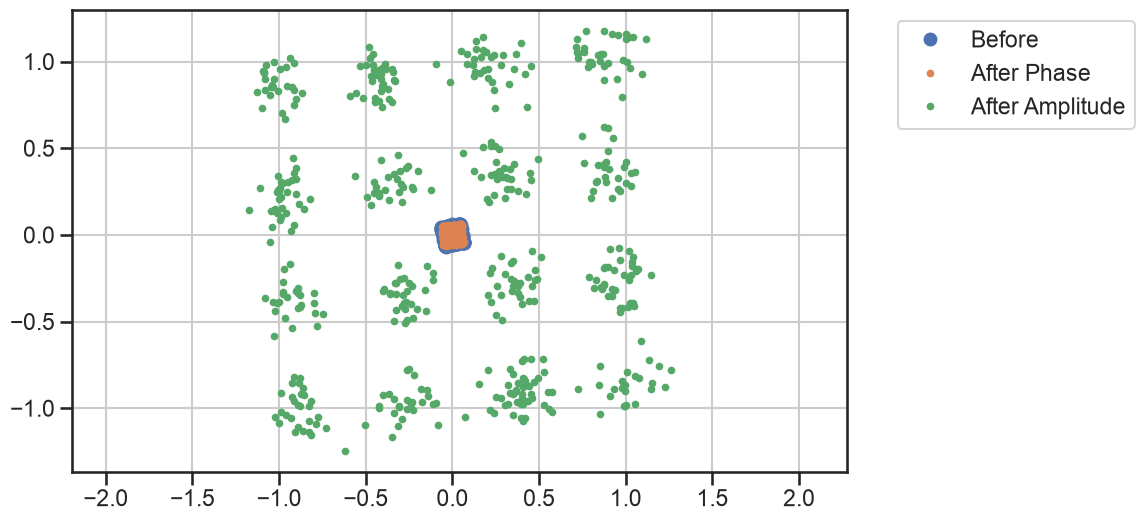

In [114]:
# Scatter plot of input before and after phase and amplitude correcetions
plt.plot(Z_hat[:Ns].real, Z_hat[:Ns].imag, 'o', label='Before')
plt.plot(x[:Ns].real, x[:Ns].imag, '.', label='After Phase')
plt.plot(y[:Ns].real, y[:Ns].imag, '.', label='After Amplitude')
plt.grid()
plt.axis('equal')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()